# Task 7: Rating & Recommendation Distribution Analysis

**Objective:** Analyze the distribution of ratings and recommendations using advanced statistical techniques:
- Gaussian Mixture Modeling (GMM) with BIC/AIC model selection
- Anomaly detection (Isolation Forest + Z-score)
- Customer segmentation (KMeans clustering)

**Input:** `data/processed/womens_clothing_scaled.csv`

## 1. Setup & Imports

In [4]:
import os
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')

# ── Logging setup ──────────────────────────────────────────────────────────────
os.makedirs('../../logs', exist_ok=True)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    handlers=[
        logging.FileHandler('../../logs/task_7.log', mode='w'),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger('Task7')
logger.info('Task 7 started.')

# ── Style ───────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0f0f1a',
    'axes.facecolor': '#1a1a2e',
    'axes.edgecolor': '#444466',
    'axes.labelcolor': '#e0e0ff',
    'xtick.color': '#c0c0e0',
    'ytick.color': '#c0c0e0',
    'text.color': '#e0e0ff',
    'grid.color': '#2a2a4a',
    'grid.linestyle': '--',
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
})

PALETTE = ['#7c5cbf', '#e96479', '#f5a623', '#4fc3f7', '#81c784', '#ff8a65']
os.makedirs('../../reports', exist_ok=True)

print('✅ Setup complete.')

2026-11-18 14:33:15,884 | INFO | Task 7 started.


✅ Setup complete.


## 2. Load Data

In [5]:
df = pd.read_csv('../data/processed/womens_clothing_scaled.csv')
logger.info(f'Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Shape: {df.shape}')
df.head()

2026-11-18 14:33:15,915 | INFO | Dataset loaded: 1539 rows × 40 columns


Shape: (1539, 40)


,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,1.545894,0.210526,EUR,100,False,-0.160714,-0.126328,-0.149871,...,zgrdejia,(568 notes),-0.338893,0.344750,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,0.000000,0.631579,EUR,12350,True,-0.714286,2.340614,2.516796,...,sarahouse,"83 % avis positifs (17,752 notes)",0.424450,-0.601793,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,0.000000,1.736842,EUR,100,False,-0.500000,-0.173554,-0.204134,...,hxt520,86 % avis positifs (295 notes),-0.351021,-0.228892,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,0.000000,-0.105263,EUR,5000,True,0.321429,0.493506,0.545220,...,allenfan,"(23,832 notes)",0.694534,-0.102309,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,-1.020290,-0.368421,EUR,100,True,-1.339286,-0.166470,-0.201550,...,happyhorses,"85 % avis positifs (14,482 notes)",0.279191,-0.180261,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


In [6]:
# ── Identify target columns ─────────────────────────────────────────────────────
RATING_COL = None
REC_COL    = None

for col in df.columns:
    cl = col.lower()
    if 'rating' in cl and RATING_COL is None:
        RATING_COL = col
    if ('recommend' in cl or 'rec' in cl) and REC_COL is None:
        REC_COL = col

print(f'Rating column    : {RATING_COL}')
print(f'Recommend column : {REC_COL}')
logger.info(f'Rating col: {RATING_COL}, Recommend col: {REC_COL}')

2026-11-18 14:33:15,944 | INFO | Rating col: rating, Recommend col: None


Rating column    : rating
Recommend column : None


## 3. Raw Distribution Visualization

2026-11-18 14:33:16,275 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-18 14:33:16,277 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


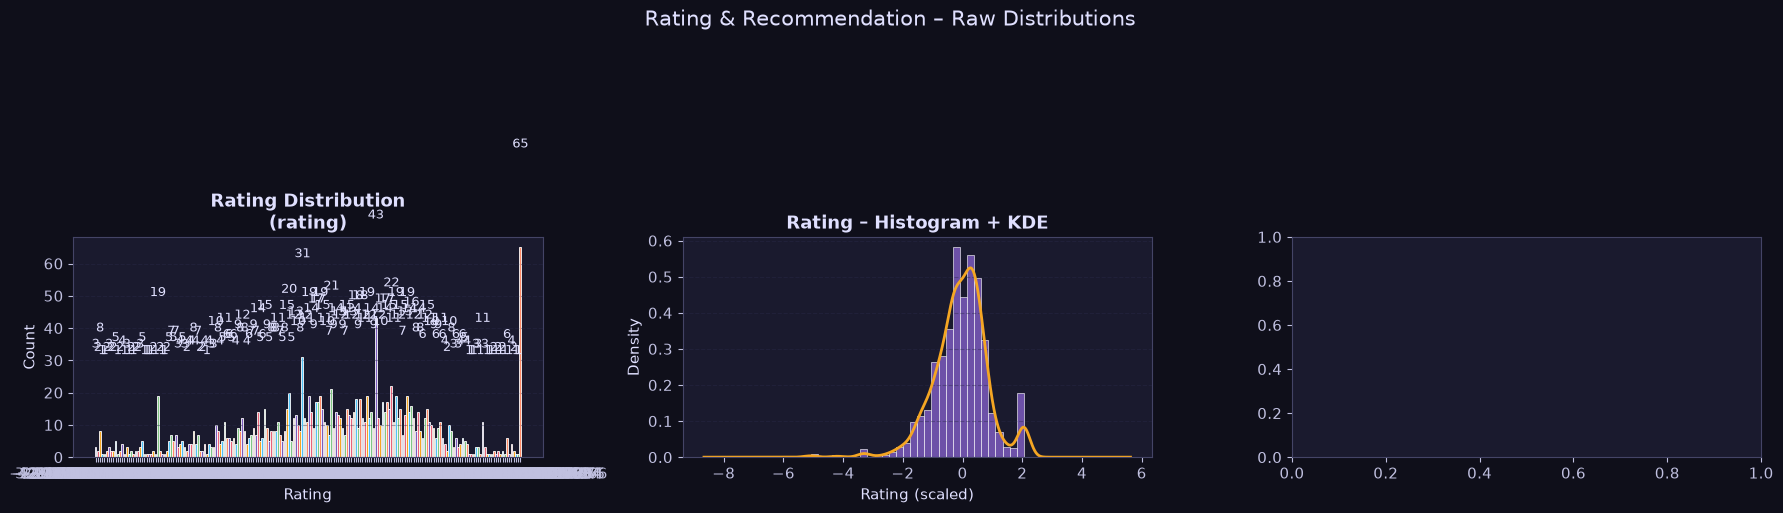

2026-11-18 14:33:22,599 | INFO | Raw distribution plots saved.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Rating & Recommendation – Raw Distributions', fontsize=15, y=1.02, color='#e0e0ff')

if RATING_COL:
    rating_counts = df[RATING_COL].value_counts().sort_index()
    bars = axes[0].bar(rating_counts.index.astype(str), rating_counts.values,
                       color=PALETTE[:len(rating_counts)], edgecolor='white', linewidth=0.6)
    for bar, val in zip(bars, rating_counts.values):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                     f'{val:,}', ha='center', va='bottom', fontsize=9, color='#e0e0ff')
    axes[0].set_title(f'Rating Distribution\n({RATING_COL})')
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Count')
    axes[0].yaxis.grid(True, alpha=0.4)

if RATING_COL:
    axes[1].hist(df[RATING_COL].dropna(), bins=30, color='#7c5cbf', edgecolor='white',
                 linewidth=0.5, alpha=0.85, density=True)
    df[RATING_COL].dropna().plot.kde(ax=axes[1], color='#f5a623', linewidth=2)
    axes[1].set_title('Rating – Histogram + KDE')
    axes[1].set_xlabel('Rating (scaled)')
    axes[1].set_ylabel('Density')
    axes[1].yaxis.grid(True, alpha=0.4)

if REC_COL:
    rec_counts = df[REC_COL].value_counts()
    wedge_colors = ['#4fc3f7', '#e96479']
    axes[2].pie(rec_counts.values, labels=[f'Rec={v}' for v in rec_counts.index],
                colors=wedge_colors[:len(rec_counts)], autopct='%1.1f%%',
                startangle=140, textprops={'color': '#e0e0ff'},
                wedgeprops={'edgecolor': '#0f0f1a', 'linewidth': 2})
    axes[2].set_title(f'Recommendation Distribution\n({REC_COL})')
    axes[2].set_facecolor('#0f0f1a')

plt.tight_layout()
plt.savefig('../../reports/task_7_raw_distributions.png', dpi=150, bbox_inches='tight',
            facecolor='#0f0f1a')
plt.show()
logger.info('Raw distribution plots saved.')

## 4. Recommendation Rate by Rating

In [8]:
if RATING_COL and REC_COL:
    rec_rate = df.groupby(RATING_COL)[REC_COL].agg(['mean', 'count']).reset_index()
    rec_rate.columns = ['Rating', 'Rec_Rate', 'Count']

    fig, ax1 = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor('#0f0f1a')

    bars = ax1.bar(rec_rate['Rating'].astype(str), rec_rate['Rec_Rate'],
                   color='#7c5cbf', alpha=0.8, edgecolor='white', linewidth=0.6, label='Rec Rate')
    ax1.set_ylabel('Recommendation Rate', color='#e0e0ff')
    ax1.set_xlabel('Rating')
    ax1.set_title('Recommendation Rate by Rating', fontsize=14)
    ax1.yaxis.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.1)
    for bar, val in zip(bars, rec_rate['Rec_Rate']):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.1%}', ha='center', va='bottom', fontsize=9, color='#f5a623')

    ax2 = ax1.twinx()
    ax2.plot(rec_rate['Rating'].astype(str), rec_rate['Count'],
             color='#f5a623', marker='o', linewidth=2, label='Count')
    ax2.set_ylabel('Count', color='#f5a623')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')

    plt.tight_layout()
    plt.savefig('../../reports/task_7_rec_rate_by_rating.png', dpi=150, bbox_inches='tight',
                facecolor='#0f0f1a')
    plt.show()
    logger.info('Recommendation rate by rating chart saved.')
    print(rec_rate.to_string(index=False))
else:
    print('⚠️  Rating or Recommendation column not found – skipping this section.')

⚠️  Rating or Recommendation column not found – skipping this section.


## 5. Gaussian Mixture Modeling (GMM)

2026-11-18 14:33:23,225 | INFO | Best GMM components – BIC: 4, AIC: 7


Best components (BIC): 4  |  Best components (AIC): 7


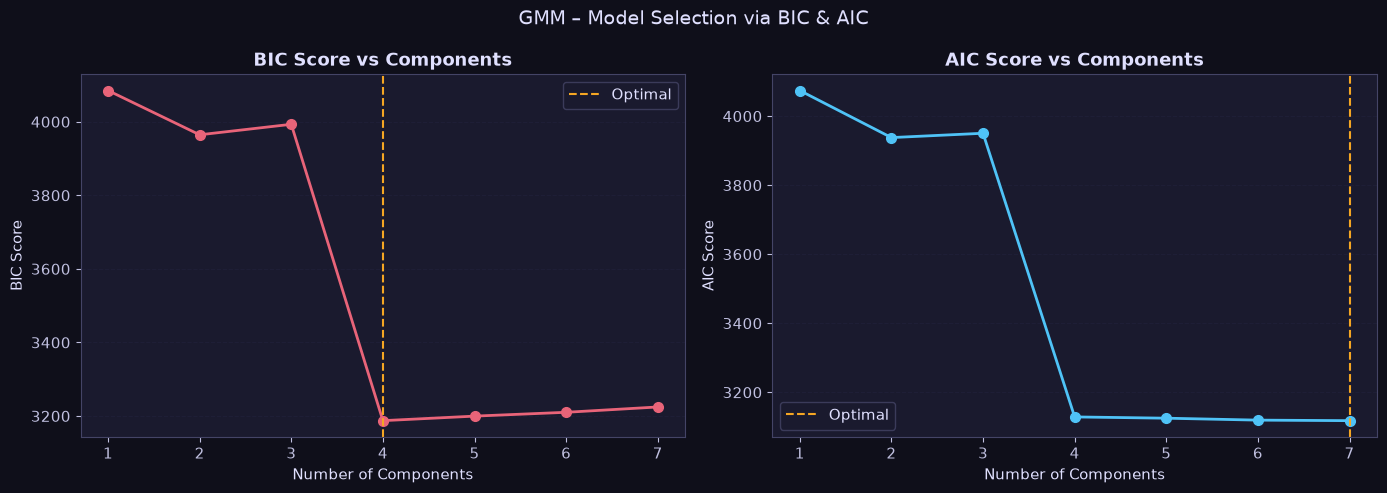

2026-11-18 14:33:23,818 | INFO | GMM model selection plot saved.


In [9]:
if RATING_COL:
    X_gmm = df[RATING_COL].dropna().values.reshape(-1, 1)

    # ── BIC / AIC model selection ──────────────────────────────────────────────
    n_components_range = range(1, 8)
    bic_scores = []
    aic_scores = []

    for n in n_components_range:
        gmm = GaussianMixture(n_components=n, covariance_type='full',
                              random_state=42, max_iter=300)
        gmm.fit(X_gmm)
        bic_scores.append(gmm.bic(X_gmm))
        aic_scores.append(gmm.aic(X_gmm))

    best_n_bic = n_components_range[np.argmin(bic_scores)]
    best_n_aic = n_components_range[np.argmin(aic_scores)]
    best_n     = best_n_bic
    logger.info(f'Best GMM components – BIC: {best_n_bic}, AIC: {best_n_aic}')
    print(f'Best components (BIC): {best_n_bic}  |  Best components (AIC): {best_n_aic}')

    # ── BIC/AIC plot ──────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('GMM – Model Selection via BIC & AIC', fontsize=14, color='#e0e0ff')

    for ax, scores, label, color in [
        (axes[0], bic_scores, 'BIC', '#e96479'),
        (axes[1], aic_scores, 'AIC', '#4fc3f7')
    ]:
        ax.plot(list(n_components_range), scores, marker='o', color=color,
                linewidth=2, markersize=7)
        ax.axvline(x=(best_n_bic if label == 'BIC' else best_n_aic),
                   color='#f5a623', linestyle='--', linewidth=1.5, label='Optimal')
        ax.set_title(f'{label} Score vs Components')
        ax.set_xlabel('Number of Components')
        ax.set_ylabel(f'{label} Score')
        ax.legend()
        ax.yaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_7_gmm_model_selection.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('GMM model selection plot saved.')

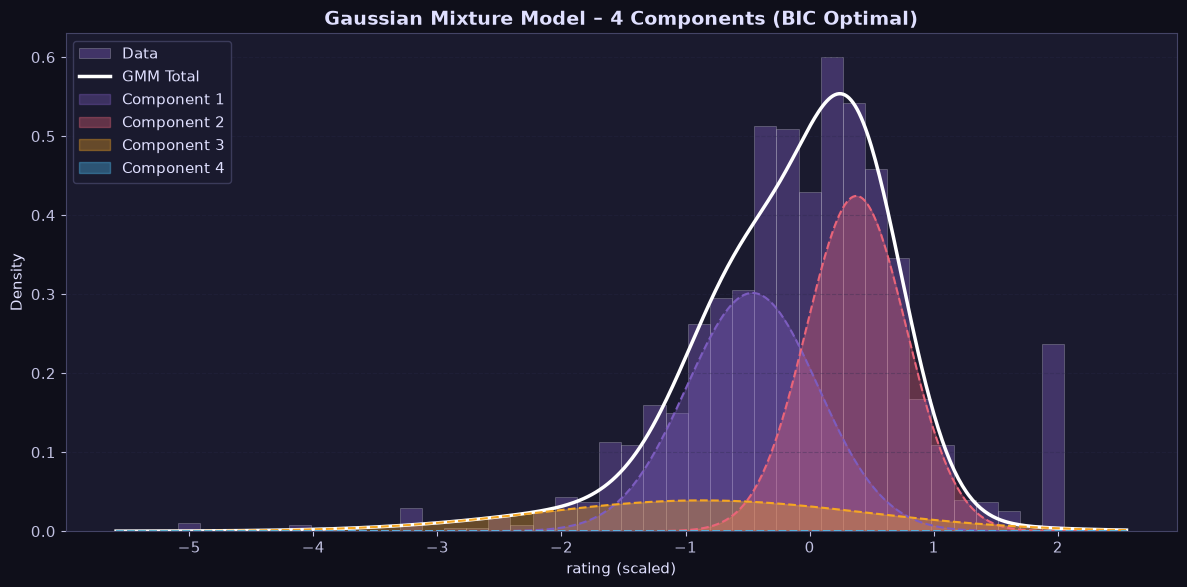

2026-11-18 14:33:24,644 | INFO | GMM component summary saved.


,Component,Weight,Mean,Variance
0,1,0.4007,-0.4612,0.2810
1,2,0.4283,0.3766,0.1622
2,3,0.1288,-0.8678,1.7368
3,4,0.0422,2.0536,0.0000


In [10]:
if RATING_COL:
    # ── Fit best GMM ──────────────────────────────────────────────────────────
    best_gmm = GaussianMixture(n_components=best_n, covariance_type='full',
                               random_state=42, max_iter=300)
    best_gmm.fit(X_gmm)

    x_range = np.linspace(X_gmm.min() - 0.5, X_gmm.max() + 0.5, 500).reshape(-1, 1)
    log_prob = best_gmm.score_samples(x_range)
    total_density = np.exp(log_prob)

    # Component densities
    responsibilities = best_gmm.predict_proba(x_range)

    fig, ax = plt.subplots(figsize=(12, 6))
    fig.patch.set_facecolor('#0f0f1a')

    ax.hist(X_gmm.ravel(), bins=40, density=True, alpha=0.4,
            color='#7c5cbf', edgecolor='white', linewidth=0.4, label='Data')
    ax.plot(x_range.ravel(), total_density, color='white', linewidth=2.5, label='GMM Total')

    for k in range(best_n):
        component_density = responsibilities[:, k] * total_density
        ax.fill_between(x_range.ravel(), component_density, alpha=0.35,
                        color=PALETTE[k % len(PALETTE)], label=f'Component {k+1}')
        ax.plot(x_range.ravel(), component_density, color=PALETTE[k % len(PALETTE)],
                linewidth=1.5, linestyle='--')

    ax.set_title(f'Gaussian Mixture Model – {best_n} Components (BIC Optimal)', fontsize=14)
    ax.set_xlabel(f'{RATING_COL} (scaled)')
    ax.set_ylabel('Density')
    ax.legend(loc='upper left')
    ax.yaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_7_gmm_components.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()

    # ── GMM summary table ─────────────────────────────────────────────────────
    gmm_summary = pd.DataFrame({
        'Component': range(1, best_n + 1),
        'Weight':    best_gmm.weights_.round(4),
        'Mean':      best_gmm.means_.ravel().round(4),
        'Variance':  best_gmm.covariances_.ravel().round(4)
    })
    gmm_summary.to_csv('../../reports/task_7_gmm_summary.csv', index=False)
    logger.info('GMM component summary saved.')
    display(gmm_summary)

## 6. Anomaly Detection

In [11]:
# ── Select numerical features for anomaly detection ───────────────────────────
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'Numerical columns: {num_cols}')

# Use up to 5 most relevant columns
feature_priority = []
for col in num_cols:
    cl = col.lower()
    if any(k in cl for k in ['rating', 'age', 'count', 'review', 'helpful']):
        feature_priority.append(col)

if len(feature_priority) < 2:
    feature_priority = num_cols[:5]

X_anom = df[feature_priority].dropna()
print(f'Anomaly detection features: {feature_priority}')
logger.info(f'Anomaly features: {feature_priority}')

2026-11-18 14:33:24,664 | INFO | Anomaly features: ['rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'badges_count', 'countries_shipped_to', 'merchant_rating_count', 'merchant_rating']


Numerical columns: ['price', 'retail_price', 'units_sold', 'rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'badges_count', 'product_variation_inventory', 'shipping_option_price', 'countries_shipped_to', 'inventory_total', 'merchant_rating_count', 'merchant_rating']
Anomaly detection features: ['rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'badges_count', 'countries_shipped_to', 'merchant_rating_count', 'merchant_rating']


In [12]:
# ── Isolation Forest ──────────────────────────────────────────────────────────
iso = IsolationForest(contamination=0.05, random_state=42, n_estimators=200)
iso_preds = iso.fit_predict(X_anom)
iso_scores = iso.decision_function(X_anom)

X_anom = X_anom.copy()
X_anom['IsoForest_Label'] = iso_preds      # -1 = anomaly, 1 = normal
X_anom['IsoForest_Score'] = iso_scores

n_anomalies_iso = (iso_preds == -1).sum()
print(f'Isolation Forest anomalies detected: {n_anomalies_iso} ({n_anomalies_iso/len(X_anom)*100:.1f}%)')
logger.info(f'Isolation Forest anomalies: {n_anomalies_iso}')

2026-11-18 14:33:25,238 | INFO | Isolation Forest anomalies: 77


Isolation Forest anomalies detected: 77 (5.0%)


In [13]:
# ── Z-Score anomaly flagging ───────────────────────────────────────────────────
z_scores = np.abs(stats.zscore(X_anom[feature_priority]))
X_anom['ZScore_Anomaly'] = (z_scores > 3).any(axis=1).astype(int)

n_anomalies_z = X_anom['ZScore_Anomaly'].sum()
print(f'Z-Score anomalies (|z|>3): {n_anomalies_z} ({n_anomalies_z/len(X_anom)*100:.1f}%)')
logger.info(f'Z-Score anomalies: {n_anomalies_z}')

2026-11-18 14:33:25,257 | INFO | Z-Score anomalies: 32


Z-Score anomalies (|z|>3): 32 (2.1%)


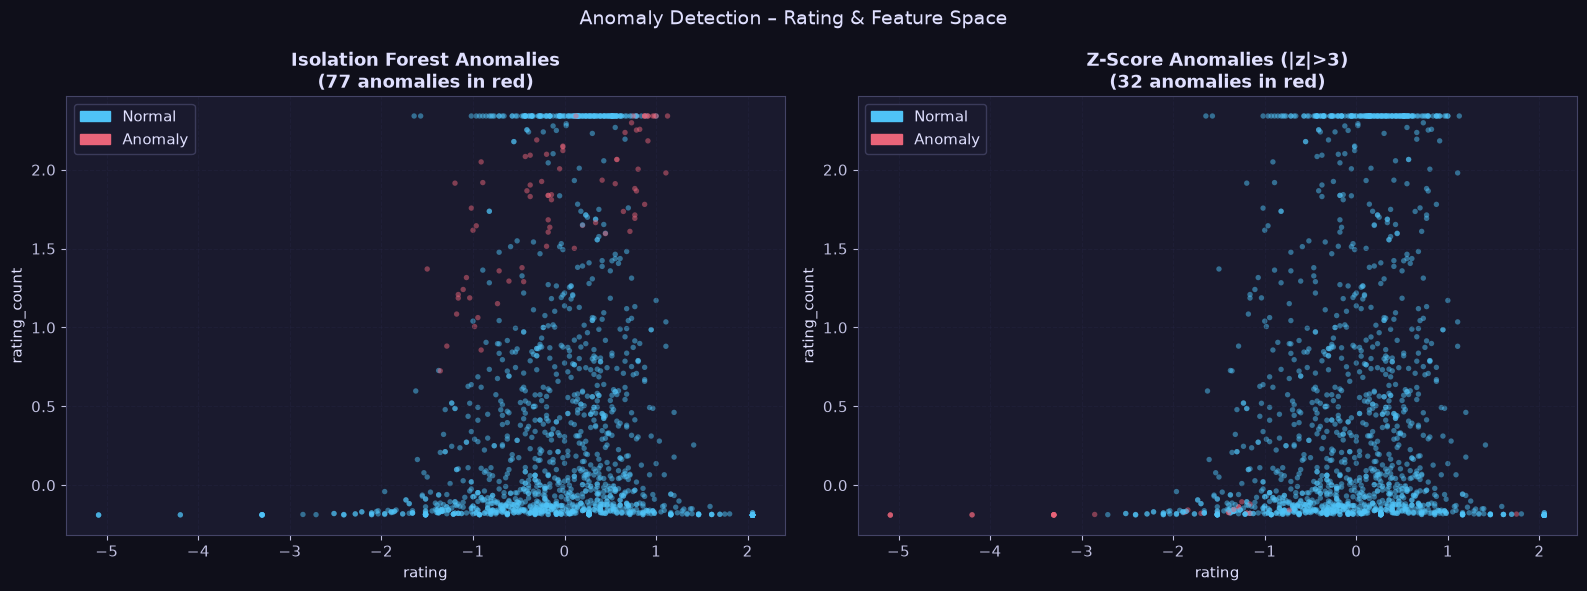

2026-11-18 14:33:26,095 | INFO | Anomaly scatter plots saved.


In [14]:
# ── Anomaly scatter plot (first two features) ─────────────────────────────────
f1, f2 = feature_priority[0], feature_priority[min(1, len(feature_priority)-1)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Anomaly Detection – Rating & Feature Space', fontsize=14, color='#e0e0ff')

colors_iso = X_anom['IsoForest_Label'].map({1: '#4fc3f7', -1: '#e96479'})
axes[0].scatter(X_anom[f1], X_anom[f2], c=colors_iso, alpha=0.5, s=15, edgecolors='none')
axes[0].set_title(f'Isolation Forest Anomalies\n({n_anomalies_iso} anomalies in red)')
axes[0].set_xlabel(f1); axes[0].set_ylabel(f2)
patch1 = mpatches.Patch(color='#4fc3f7', label='Normal')
patch2 = mpatches.Patch(color='#e96479', label='Anomaly')
axes[0].legend(handles=[patch1, patch2])
axes[0].yaxis.grid(True, alpha=0.3); axes[0].xaxis.grid(True, alpha=0.3)

colors_z = X_anom['ZScore_Anomaly'].map({0: '#4fc3f7', 1: '#e96479'})
axes[1].scatter(X_anom[f1], X_anom[f2], c=colors_z, alpha=0.5, s=15, edgecolors='none')
axes[1].set_title(f'Z-Score Anomalies (|z|>3)\n({n_anomalies_z} anomalies in red)')
axes[1].set_xlabel(f1); axes[1].set_ylabel(f2)
axes[1].legend(handles=[patch1, patch2])
axes[1].yaxis.grid(True, alpha=0.3); axes[1].xaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_7_anomaly_detection.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Anomaly scatter plots saved.')

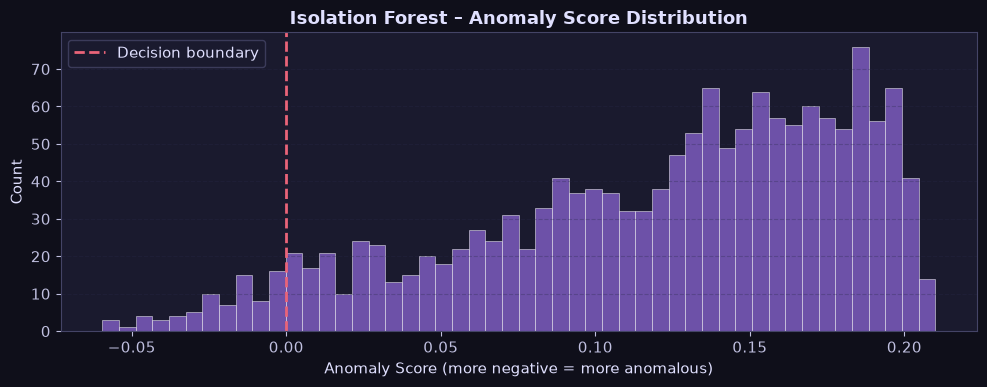

In [15]:
# ── Anomaly score distribution ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#0f0f1a')

ax.hist(X_anom['IsoForest_Score'], bins=50, color='#7c5cbf',
        edgecolor='white', linewidth=0.4, alpha=0.85)
ax.axvline(x=0, color='#e96479', linestyle='--', linewidth=2, label='Decision boundary')
ax.set_title('Isolation Forest – Anomaly Score Distribution', fontsize=13)
ax.set_xlabel('Anomaly Score (more negative = more anomalous)')
ax.set_ylabel('Count')
ax.legend(); ax.yaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_7_anomaly_score_dist.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

## 7. Customer Segmentation – KMeans Clustering

In [16]:
# ── Elbow method & Silhouette score ───────────────────────────────────────────
X_cluster_raw = df[feature_priority].dropna()
scaler = StandardScaler()
X_cluster = scaler.fit_transform(X_cluster_raw)

inertias, silhouettes = [], []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_cluster, labels, sample_size=min(5000, len(X_cluster)))
    silhouettes.append(sil)
    print(f'  k={k}  inertia={km.inertia_:.1f}  silhouette={sil:.4f}')

best_k = list(k_range)[np.argmax(silhouettes)]
print(f'\nBest k by silhouette: {best_k}')
logger.info(f'Best k by silhouette: {best_k}')

  k=2  inertia=7739.4  silhouette=0.4964
  k=3  inertia=6617.0  silhouette=0.2373
  k=4  inertia=5767.1  silhouette=0.2260


2026-11-18 14:33:27,185 | INFO | Best k by silhouette: 2


  k=5  inertia=5189.8  silhouette=0.2373
  k=6  inertia=4899.4  silhouette=0.2153
  k=7  inertia=4426.9  silhouette=0.2153
  k=8  inertia=4261.7  silhouette=0.2114

Best k by silhouette: 2


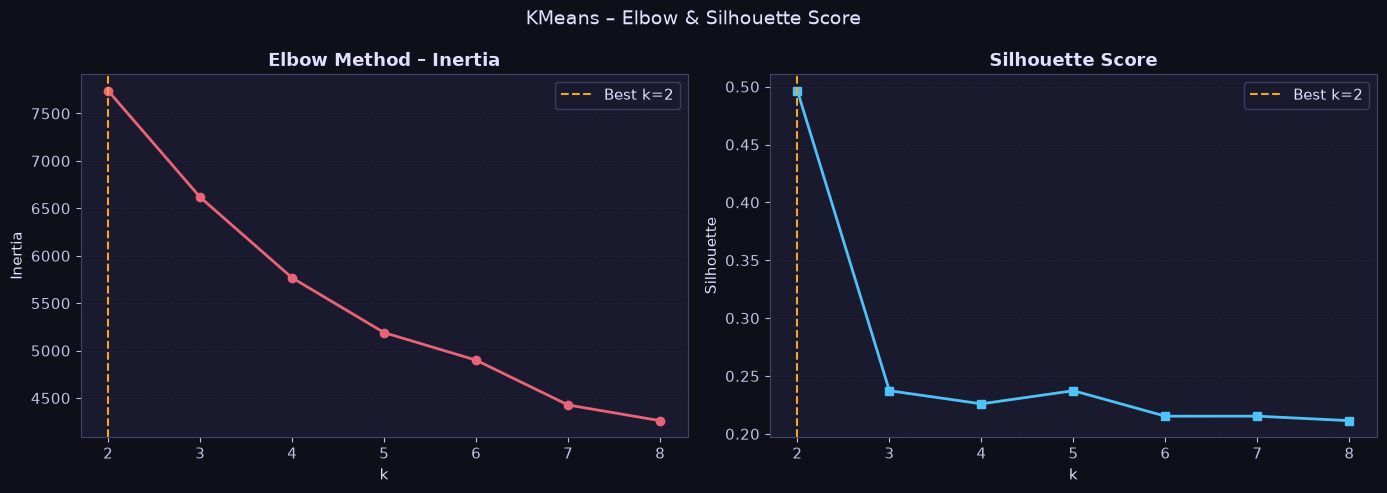

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('KMeans – Elbow & Silhouette Score', fontsize=14, color='#e0e0ff')

axes[0].plot(list(k_range), inertias, marker='o', color='#e96479', linewidth=2)
axes[0].axvline(x=best_k, color='#f5a623', linestyle='--', linewidth=1.5, label=f'Best k={best_k}')
axes[0].set_title('Elbow Method – Inertia'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].legend(); axes[0].yaxis.grid(True, alpha=0.3)

axes[1].plot(list(k_range), silhouettes, marker='s', color='#4fc3f7', linewidth=2)
axes[1].axvline(x=best_k, color='#f5a623', linestyle='--', linewidth=1.5, label=f'Best k={best_k}')
axes[1].set_title('Silhouette Score'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[1].legend(); axes[1].yaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_7_kmeans_selection.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

In [18]:
# ── Fit best KMeans ───────────────────────────────────────────────────────────
best_km = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
X_cluster_raw = X_cluster_raw.copy()
X_cluster_raw['Cluster'] = best_km.fit_predict(X_cluster)

# ── Cluster profiles ──────────────────────────────────────────────────────────
cluster_profiles = X_cluster_raw.groupby('Cluster').agg(
    Count=('Cluster', 'count'),
    **{f'{col}_mean': (col, 'mean') for col in feature_priority},
    **{f'{col}_std':  (col, 'std')  for col in feature_priority}
).round(3).reset_index()

# Add recommendation rate per cluster if available
if REC_COL:
    idx = X_cluster_raw.index
    rec_cluster = df.loc[idx, REC_COL].fillna(0)
    X_cluster_raw['Recommendation'] = rec_cluster.values
    rec_rate_cluster = X_cluster_raw.groupby('Cluster')['Recommendation'].mean().round(3)
    cluster_profiles = cluster_profiles.merge(
        rec_rate_cluster.rename('Rec_Rate').reset_index(), on='Cluster')

cluster_profiles.to_csv('../../reports/task_7_cluster_profiles.csv', index=False)
logger.info('Cluster profiles saved.')
display(cluster_profiles)

2026-11-18 14:33:28,138 | INFO | Cluster profiles saved.


,Cluster,Count,rating_mean,rating_count_mean,rating_five_count_mean,rating_four_count_mean,rating_three_count_mean,rating_two_count_mean,rating_one_count_mean,badges_count_mean,...,rating_count_std,rating_five_count_std,rating_four_count_std,rating_three_count_std,rating_two_count_std,rating_one_count_std,badges_count_std,countries_shipped_to_std,merchant_rating_count_std,merchant_rating_std
0,0,1199,-0.069,0.058,0.054,0.049,0.038,0.049,0.048,0.0,...,0.325,0.363,0.325,0.319,0.334,0.389,0.0,0.930,0.766,0.884
1,1,340,0.024,1.981,2.055,2.005,2.047,1.960,1.936,0.0,...,0.472,0.604,0.508,0.531,0.569,0.630,0.0,0.849,0.945,0.592


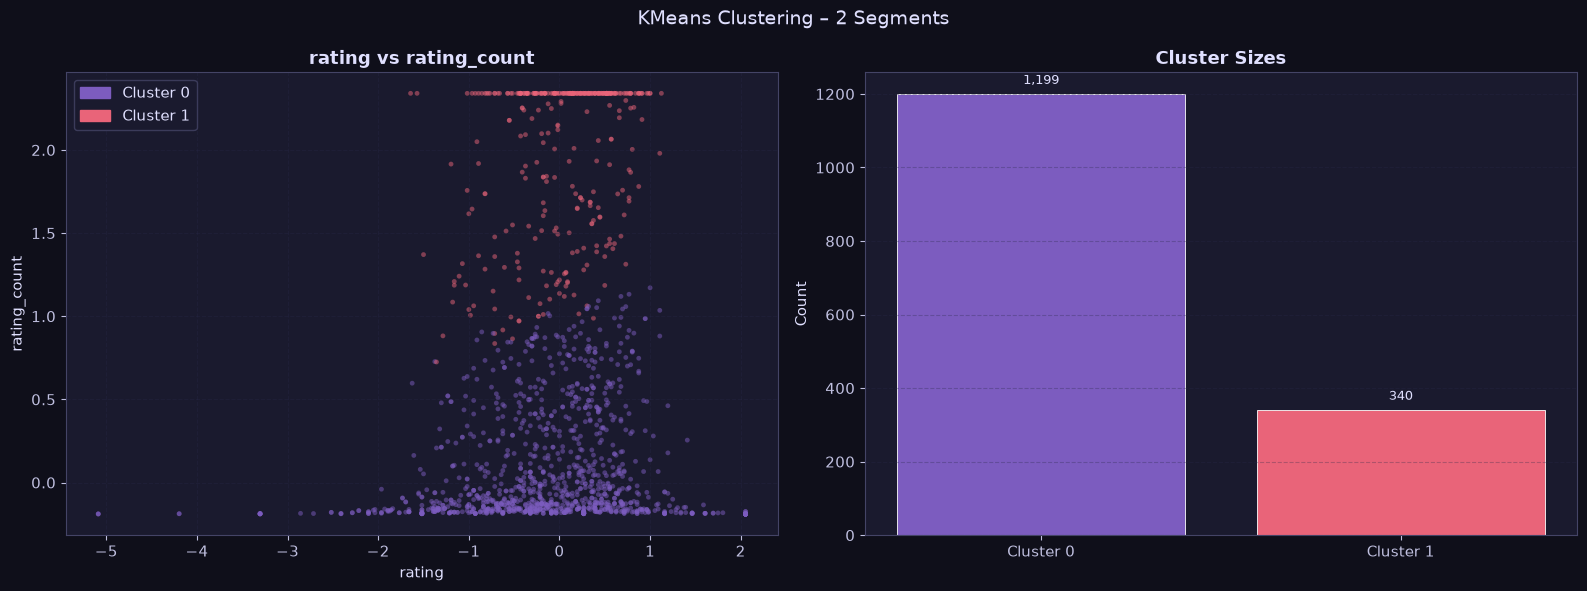

2026-11-18 14:33:28,790 | INFO | Cluster scatter plot saved.


In [19]:
# ── Cluster scatter plot ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'KMeans Clustering – {best_k} Segments', fontsize=14, color='#e0e0ff')

cluster_colors = [PALETTE[i % len(PALETTE)] for i in X_cluster_raw['Cluster']]
axes[0].scatter(X_cluster_raw[f1], X_cluster_raw[f2],
                c=cluster_colors, alpha=0.5, s=12, edgecolors='none')
axes[0].set_title(f'{f1} vs {f2}')
axes[0].set_xlabel(f1); axes[0].set_ylabel(f2)
patches = [mpatches.Patch(color=PALETTE[i % len(PALETTE)], label=f'Cluster {i}')
           for i in range(best_k)]
axes[0].legend(handles=patches, loc='best')
axes[0].yaxis.grid(True, alpha=0.3); axes[0].xaxis.grid(True, alpha=0.3)

# Cluster size bar chart
cluster_counts = X_cluster_raw['Cluster'].value_counts().sort_index()
bar_colors = [PALETTE[i % len(PALETTE)] for i in cluster_counts.index]
axes[1].bar([f'Cluster {i}' for i in cluster_counts.index],
            cluster_counts.values, color=bar_colors, edgecolor='white', linewidth=0.6)
for i, (c, v) in enumerate(zip(cluster_counts.index, cluster_counts.values)):
    axes[1].text(i, v + 20, f'{v:,}', ha='center', va='bottom', fontsize=9, color='#e0e0ff')
axes[1].set_title('Cluster Sizes'); axes[1].set_ylabel('Count')
axes[1].yaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_7_cluster_scatter.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Cluster scatter plot saved.')

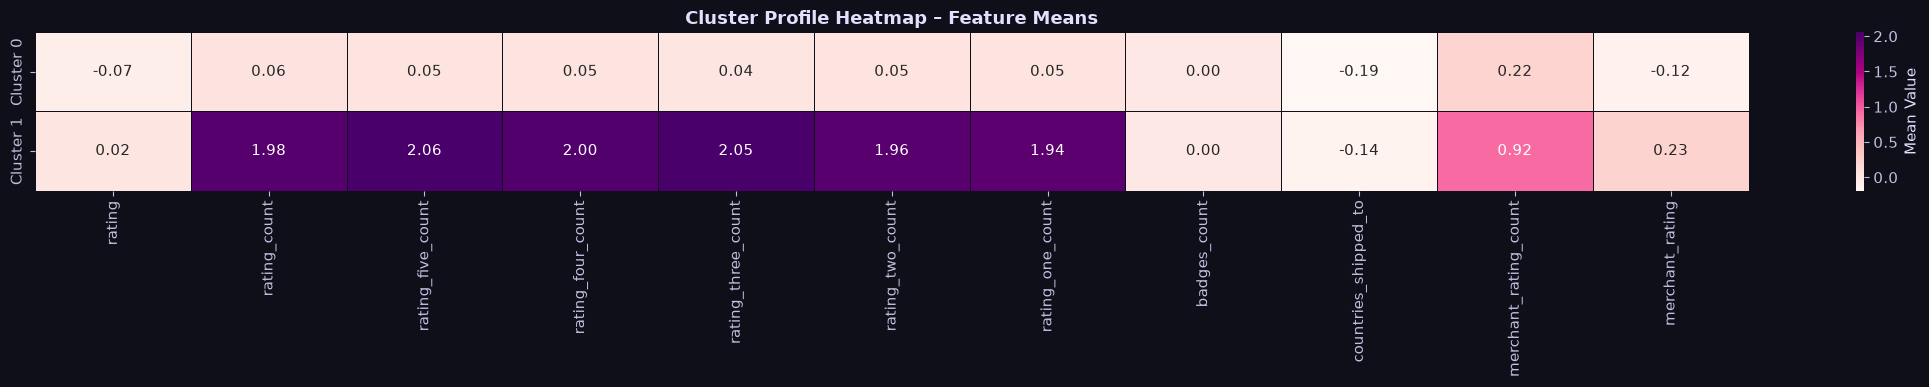

2026-11-18 14:33:29,547 | INFO | Cluster heatmap saved.


In [20]:
# ── Cluster Heatmap Profile ───────────────────────────────────────────────────
mean_cols = [c for c in cluster_profiles.columns if c.endswith('_mean')]
heat_data = cluster_profiles[mean_cols].set_index(cluster_profiles['Cluster'])
heat_data.index = [f'Cluster {i}' for i in heat_data.index]
heat_data.columns = [c.replace('_mean', '') for c in heat_data.columns]

fig, ax = plt.subplots(figsize=(max(10, len(mean_cols)*2), 4))
fig.patch.set_facecolor('#0f0f1a')
sns.heatmap(heat_data, annot=True, fmt='.2f', cmap='RdPu', ax=ax,
            linewidths=0.5, linecolor='#0f0f1a',
            cbar_kws={'label': 'Mean Value'})
ax.set_title('Cluster Profile Heatmap – Feature Means', fontsize=13)
plt.tight_layout()
plt.savefig('../../reports/task_7_cluster_heatmap.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Cluster heatmap saved.')

## 8. Save Distribution Analysis Report

In [21]:
dist_records = []
if RATING_COL:
    r = df[RATING_COL].dropna()
    dist_records.append({
        'Column': RATING_COL,
        'Count': len(r),
        'Mean': round(r.mean(), 4),
        'Median': round(r.median(), 4),
        'Std': round(r.std(), 4),
        'Min': round(r.min(), 4),
        'Max': round(r.max(), 4),
        'Skewness': round(r.skew(), 4),
        'Kurtosis': round(r.kurtosis(), 4),
        'GMM_Components': best_n,
        'IsoForest_Anomalies': int(n_anomalies_iso),
        'ZScore_Anomalies': int(n_anomalies_z),
        'KMeans_Clusters': int(best_k)
    })

if REC_COL:
    rc = df[REC_COL].dropna()
    dist_records.append({
        'Column': REC_COL,
        'Count': len(rc),
        'Mean': round(rc.mean(), 4),
        'Median': round(rc.median(), 4),
        'Std': round(rc.std(), 4),
        'Min': round(rc.min(), 4),
        'Max': round(rc.max(), 4),
        'Skewness': round(rc.skew(), 4),
        'Kurtosis': round(rc.kurtosis(), 4),
        'GMM_Components': None,
        'IsoForest_Anomalies': None,
        'ZScore_Anomalies': None,
        'KMeans_Clusters': None
    })

dist_df = pd.DataFrame(dist_records)
dist_df.to_csv('../../reports/task_7_distribution_analysis.csv', index=False)
logger.info('Distribution analysis report saved.')
print('✅ Task 7 complete. Reports saved to reports/ folder.')
display(dist_df)

2026-11-18 14:33:29,605 | INFO | Distribution analysis report saved.


✅ Task 7 complete. Reports saved to reports/ folder.


,Column,Count,Mean,Median,Std,Min,Max,Skewness,Kurtosis,GMM_Components,IsoForest_Anomalies,ZScore_Anomalies,KMeans_Clusters
0,rating,1539,-0.0485,0.0,0.9082,-5.0893,2.0536,-0.5474,2.8921,4,77,32,2
